## Phase 4: which users does item-item help most?

### Load

In [3]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.metrics import evaluate, score_users, build_test_liked
from src.recommenders import build_recommenders

LIKE_THRESHOLD = 4.0
K = 10

train = pd.read_parquet("../data/train.parquet")
test  = pd.read_parquet("../data/test.parquet")
test_liked = build_test_liked(test, LIKE_THRESHOLD)

### Build the models and confirm they match notebook 02

In [5]:
models = build_recommenders(train, LIKE_THRESHOLD)
popularity_rec = models["Popularity"]
itemitem_rec   = models["Item-item"]

# These should match notebook 02's numbers exactly
print(evaluate(popularity_rec, test_liked, k=K, n_users=1000).to_string())
print(evaluate(itemitem_rec, test_liked, k=K, n_users=1000).to_string())

recall       0.0307
precision    0.0650
ndcg         0.0789
recall       0.0429
precision    0.0980
ndcg         0.1105


### Score each user, and count how many movies they liked before the cutoff

In [7]:
pop_scores = score_users(popularity_rec, test_liked, k=K, n_users=1000)
ii_scores  = score_users(itemitem_rec, test_liked, k=K, n_users=1000)

per_user = pd.DataFrame({"pop_ndcg": pop_scores.ndcg, "ii_ndcg": ii_scores.ndcg})

# Number of movies each user liked in the training period
likes_per_user = pd.Series(np.diff(models["R_liked"].indptr), index=models["u_index"].index)
per_user["train_likes"] = likes_per_user.loc[per_user.index].values

per_user.head()

,pop_ndcg,ii_ndcg,train_likes
userId,,,
81751,0.000000,0.078398,506
34091,0.242618,0.627507,40
153300,0.000000,0.000000,101
143746,0.000000,0.000000,89
65343,0.000000,0.000000,708


### Compare the models by history length

In [9]:
bins   = [0, 20, 50, 150, np.inf]
labels = ["1-20", "21-50", "51-150", "150+"]
per_user["history"] = pd.cut(per_user.train_likes, bins=bins, labels=labels)

by_group = (per_user.groupby("history", observed=True)
            .agg(users=("ii_ndcg", "size"),
                 popularity=("pop_ndcg", "mean"),
                 item_item=("ii_ndcg", "mean")))

# How much better item-item does, as a percentage
by_group["lift"] = (by_group.item_item / by_group.popularity - 1).map("{:+.0%}".format)

by_group.round(4)

,users,popularity,item_item,lift
history,,,,
1-20,90,0.1481,0.1725,+16%
21-50,115,0.1085,0.1452,+34%
51-150,348,0.0698,0.1121,+61%
150+,447,0.0644,0.0879,+36%


### Chart for the README

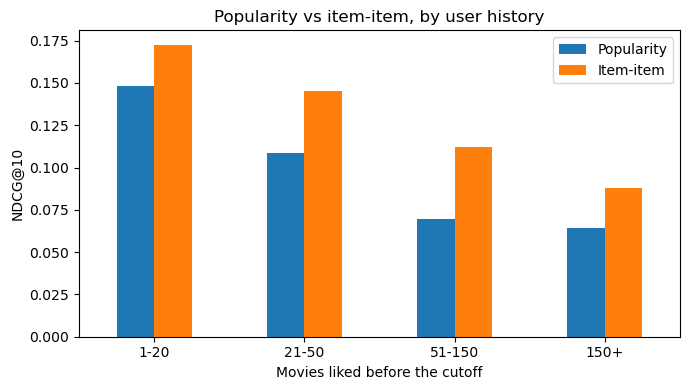

In [11]:
ax = by_group[["popularity", "item_item"]].plot.bar(rot=0, figsize=(7, 4))
ax.set_xlabel("Movies liked before the cutoff")
ax.set_ylabel("NDCG@10")
ax.set_title("Popularity vs item-item, by user history")
ax.legend(["Popularity", "Item-item"])
plt.tight_layout()
plt.savefig("../reports/figures/ndcg_by_history.png", dpi=150)
plt.show()

In [12]:
# What share of each user's test-window likes are among the 100 most-liked movies?
top100 = set(train[train.rating >= LIKE_THRESHOLD].movieId.value_counts().head(100).index)

per_user["share_top100"] = [
    len(test_liked.loc[u] & top100) / len(test_liked.loc[u]) for u in per_user.index
]

per_user.groupby("history", observed=True)["share_top100"].mean().round(3)

history
1-20      0.241
21-50     0.200
51-150    0.122
150+      0.047
Name: share_top100, dtype: float64

### Export cell for demo app

In [14]:
import os
from sklearn.preprocessing import normalize

N_MOVIES = 3000      # how many movies the demo offers
N_NEIGHBORS = 50     # similar movies kept per movie

movies = pd.read_csv("../data/ml-25m/movies.csv")
item_ids = np.sort(train.movieId.unique())          # same column order as R_liked

# 1. The most-liked movies
R_liked = models["R_liked"]
like_counts = np.asarray(R_liked.sum(axis=0)).ravel()
top_cols = np.argsort(-like_counts)[:N_MOVIES]

# 2. Cosine similarity between those movies (3,000 x 3,000, small enough to hold in memory)
R_top = normalize(R_liked[:, top_cols], axis=0)
sim = (R_top.T @ R_top).toarray()
np.fill_diagonal(sim, 0)                             # a movie isn't its own neighbor

# 3. Keep each movie's 50 most similar
rows = []
for a in range(len(top_cols)):
    best = np.argsort(-sim[a])[:N_NEIGHBORS]
    for b in best:
        rows.append((item_ids[top_cols[a]], item_ids[top_cols[b]], round(float(sim[a, b]), 4)))
neighbors = pd.DataFrame(rows, columns=["movieId", "neighborId", "similarity"])

# 4. Movie titles plus like counts (for the popularity list)
demo_movies = (pd.DataFrame({"movieId": item_ids[top_cols], "likes": like_counts[top_cols].astype(int)})
               .merge(movies, on="movieId"))

os.makedirs("../demo", exist_ok=True)
demo_movies.to_csv("../demo/movies.csv", index=False)
neighbors.to_csv("../demo/neighbors.csv", index=False)

print(f"movies: {len(demo_movies):,} rows, {os.path.getsize('../demo/movies.csv')/1e6:.1f} MB")
print(f"neighbors: {len(neighbors):,} rows, {os.path.getsize('../demo/neighbors.csv')/1e6:.1f} MB")

movies: 3,000 rows, 0.2 MB
neighbors: 150,000 rows, 2.6 MB
